In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv("downloads/retail_sales.csv")

In [3]:
df

,Order_ID,Order_Date,Customer_ID,City,Product,Category,Quantity,Unit_Price,Discount_Pct,Payment_Method,Sales_Amount
0,ORD0001,2025-03-13,CUST039,Pune,Tablet,Electronics,5.0,25795.0,0.10,UPI,116077.50
1,ORD0002,2025-03-29,CUST040,Pune,Phone,Electronics,3.0,28850.0,0.10,Net Banking,77895.00
2,ORD0003,2025-12-10,CUST038,Mumbai,Headphones,Accessories,5.0,2385.0,0.05,Card,11328.75
3,ORD0004,2025-06-10,CUST022,NaN,Phone,Electronics,4.0,17311.0,0.20,Card,55395.20
4,ORD0005,2025-02-28,CUST028,Hyderabad,Keyboard,Accessories,1.0,1247.0,0.00,Net Banking,1247.00
...,...,...,...,...,...,...,...,...,...,...,...
119,ORD0120,2025-08-31,CUST024,Pune,Mouse,Accessories,1.0,1930.0,0.10,Net Banking,1737.00
120,ORD0011,2025-09-27,CUST040,Delhi,Phone,Electronics,2.0,17675.0,0.05,Cash,33582.50
121,ORD0028,2025-07-03,CUST038,Chennai,Phone,Electronics,4.0,50559.0,0.10,UPI,182012.40
122,ORD0065,2025-03-31,CUST041,Delhi,Tablet,Electronics,2.0,37472.0,0.20,Card,59955.20


In [4]:
df.shape

(124, 11)

In [5]:
df.dtypes

Order_ID           object
Order_Date         object
Customer_ID        object
City               object
Product            object
Category           object
Quantity          float64
Unit_Price        float64
Discount_Pct      float64
Payment_Method     object
Sales_Amount      float64
dtype: object

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124 entries, 0 to 123
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        124 non-null    object 
 1   Order_Date      123 non-null    object 
 2   Customer_ID     122 non-null    object 
 3   City            121 non-null    object 
 4   Product         123 non-null    object 
 5   Category        123 non-null    object 
 6   Quantity        122 non-null    float64
 7   Unit_Price      122 non-null    float64
 8   Discount_Pct    122 non-null    float64
 9   Payment_Method  122 non-null    object 
 10  Sales_Amount    122 non-null    float64
dtypes: float64(4), object(7)
memory usage: 10.8+ KB


In [7]:
df.describe()

,Quantity,Unit_Price,Discount_Pct,Sales_Amount
count,122.000000,122.000000,122.000000,122.000000
mean,2.877049,17832.795082,0.107787,48149.171721
std,1.485900,21175.774977,0.125642,68455.149142
min,-2.000000,-500.000000,0.000000,523.600000
25%,2.000000,2307.000000,0.050000,5915.925000
50%,3.000000,6893.000000,0.100000,22119.200000
75%,4.000000,23952.750000,0.150000,62772.800000
max,5.000000,81940.000000,1.250000,365220.000000


In [8]:
df.describe(include="object").T

,count,unique,top,freq
Order_ID,124,120,ORD0011,2
Order_Date,123,101,2025-10-10,3
Customer_ID,122,42,CUST001,6
City,121,9,Hyderabad,24
Product,123,8,Keyboard,25
Category,123,3,Electronics,68
Payment_Method,122,6,UPI,31


In [9]:
df["Order_Date"]=pd.to_datetime(df["Order_Date"],errors="coerce")

In [10]:
df.dtypes

Order_ID                  object
Order_Date        datetime64[ns]
Customer_ID               object
City                      object
Product                   object
Category                  object
Quantity                 float64
Unit_Price               float64
Discount_Pct             float64
Payment_Method            object
Sales_Amount             float64
dtype: object

STANDARDIZATION

In [11]:
#checking texts

for i in df.columns:
    if df[i].dtype=="object":
        df[i]=df[i].str.strip()
        df[i]=df[i].str.title()

In [12]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'City', 'Product', 'Category',
       'Quantity', 'Unit_Price', 'Discount_Pct', 'Payment_Method',
       'Sales_Amount'],
      dtype='object')

DUPLICATES_CHECKING

In [13]:
print(df.duplicated().sum())

4


In [14]:
df[df.duplicated()]

,Order_ID,Order_Date,Customer_ID,City,Product,Category,Quantity,Unit_Price,Discount_Pct,Payment_Method,Sales_Amount
120,Ord0011,2025-09-27,Cust040,Delhi,Phone,Electronics,2.0,17675.0,0.05,Cash,33582.5
121,Ord0028,2025-07-03,Cust038,Chennai,Phone,Electronics,4.0,50559.0,0.10,Upi,182012.4
122,Ord0065,2025-03-31,Cust041,Delhi,Tablet,Electronics,2.0,37472.0,0.20,Card,59955.2
123,Ord0091,2025-11-08,Cust045,Delhi,Tablet,Electronics,2.0,20136.0,0.05,Card,38258.4


In [15]:
df=df.drop_duplicates()

In [16]:
print(df.shape)

(120, 11)


NULL/MISSING_VALUES

In [17]:
df.isnull().sum()

Order_ID          0
Order_Date        7
Customer_ID       2
City              3
Product           1
Category          1
Quantity          2
Unit_Price        2
Discount_Pct      2
Payment_Method    2
Sales_Amount      2
dtype: int64

In [18]:
nulls=pd.DataFrame({
    "null_values":df.isnull().sum()}
            )

In [19]:
nulls.sort_values("null_values",ascending=False)

,null_values
Order_Date,7
City,3
Customer_ID,2
Quantity,2
Unit_Price,2
Discount_Pct,2
Payment_Method,2
Sales_Amount,2
Product,1
Category,1


In [20]:
dff=df.copy()
dff["Product"]=dff["Product"].fillna(dff["Product"].mode()[0])

In [21]:
dff["Category"]=dff["Category"].fillna(dff["Category"].mode()[0])

In [22]:
dff["Payment_Method"]=dff["Payment_Method"].fillna(dff.Payment_Method.mode()[0])

In [23]:
dff["City"]=dff["City"].fillna(dff["City"].mode()[0])

In [24]:
dff["Order_Date"]=dff["Order_Date"].ffill()

In [25]:
dff["Customer_ID"]=dff["Customer_ID"].ffill()

In [26]:
dff.shape

(120, 11)

In [27]:
dff.isnull().sum()

Order_ID          0
Order_Date        0
Customer_ID       0
City              0
Product           0
Category          0
Quantity          2
Unit_Price        2
Discount_Pct      2
Payment_Method    0
Sales_Amount      2
dtype: int64

In [28]:
dff["Quantity"]=dff["Quantity"].fillna(dff["Quantity"].mean())

In [29]:
dff["Unit_Price"]=dff["Unit_Price"].fillna(dff["Unit_Price"].median())

In [30]:
dff["Discount_Pct"]=dff["Discount_Pct"].fillna(dff["Discount_Pct"].median())

In [31]:
dff["Sales_Amount"]=dff["Sales_Amount"].fillna(dff["Sales_Amount"].median())

In [32]:
dff.isnull().sum()

Order_ID          0
Order_Date        0
Customer_ID       0
City              0
Product           0
Category          0
Quantity          0
Unit_Price        0
Discount_Pct      0
Payment_Method    0
Sales_Amount      0
dtype: int64

INVALID_VALUES

In [33]:
dff=dff[dff["Quantity"]>0]

In [34]:
dff[dff["Unit_Price"]<0]

,Order_ID,Order_Date,Customer_ID,City,Product,Category,Quantity,Unit_Price,Discount_Pct,Payment_Method,Sales_Amount
44,Ord0045,2025-12-26,Cust032,Delhi,Laptop,Electronics,2.0,-500.0,0.1,Net Banking,121941.0


In [35]:
dff=dff[dff["Unit_Price"]>0]

In [36]:
#discount percent in range between 0 and 1

In [37]:
dff=dff[(dff["Discount_Pct"]>=0) & (dff["Discount_Pct"]<=1)]

In [38]:
#extracting new columns from order_date

dff["Year"] = dff["Order_Date"].dt.year

dff["Month"] = dff["Order_Date"].dt.month

dff["Month_Name"] = dff["Order_Date"].dt.strftime("%B")

In [39]:
dff["Sales_Category"] = pd.cut(
    dff["Sales_Amount"],
    bins=[-float("inf"), 5000, 20000, float("inf")],
    labels=["Low", "Medium", "High"]
)

In [40]:
dff

,Order_ID,Order_Date,Customer_ID,City,Product,Category,Quantity,Unit_Price,Discount_Pct,Payment_Method,Sales_Amount,Year,Month,Month_Name,Sales_Category
0,Ord0001,2025-03-13,Cust039,Pune,Tablet,Electronics,5.0,25795.0,0.10,Upi,116077.50,2025,3,March,High
1,Ord0002,2025-03-29,Cust040,Pune,Phone,Electronics,3.0,28850.0,0.10,Net Banking,77895.00,2025,3,March,High
2,Ord0003,2025-12-10,Cust038,Mumbai,Headphones,Accessories,5.0,2385.0,0.05,Card,11328.75,2025,12,December,Medium
3,Ord0004,2025-06-10,Cust022,Hyderabad,Phone,Electronics,4.0,17311.0,0.20,Card,55395.20,2025,6,June,High
4,Ord0005,2025-02-28,Cust028,Hyderabad,Keyboard,Accessories,1.0,1247.0,0.00,Net Banking,1247.00,2025,2,February,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,Ord0116,2025-08-21,Cust036,Pune,Laptop,Electronics,2.0,77563.0,0.10,Card,139613.40,2025,8,August,High
116,Ord0117,2025-08-24,Cust041,Chennai,Tablet,Electronics,2.0,36069.0,0.00,Card,72138.00,2025,8,August,High
117,Ord0118,2025-11-16,Cust045,Hyderabad,Keyboard,Accessories,4.0,2041.0,0.05,Cash,7755.80,2025,11,November,Medium
118,Ord0119,2025-07-17,Cust004,Delhi,Mouse,Accessories,5.0,1612.0,0.20,Cash,6448.00,2025,7,July,Medium


In [41]:
#important KPI's

total_sales = dff["Sales_Amount"].sum()

total_units = dff["Quantity"].sum()

total_orders = dff["Order_ID"].nunique()

unique_customers = dff["Customer_ID"].nunique()

average_order_value = total_sales / total_orders

print("Total Sales:", round(total_sales, 2))
print("Total Units Sold:", round(total_units),2)
print("Total Orders:", total_orders)
print("Unique Customers:", unique_customers)
print("Average Order Value:", round(average_order_value, 2))

Total Sales: 5128771.45
Total Units Sold: 342 2
Total Orders: 117
Unique Customers: 42
Average Order Value: 43835.65


In [42]:
#finding best selling product

product_total_sum=dff.groupby("Product")["Sales_Amount"].sum().sort_values(ascending=False)
product_total_sum

Product
Laptop        1940357.350
Phone         1120338.050
Tablet         986557.700
Monitor        699112.950
Keyboard       172862.300
Headphones     157470.675
Mouse           52072.425
Name: Sales_Amount, dtype: float64

[]

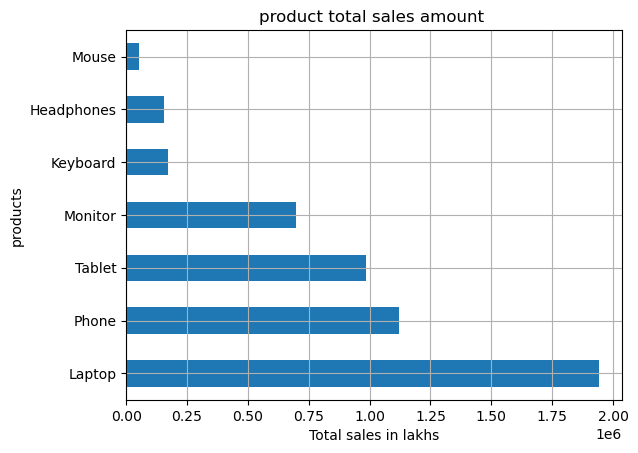

In [107]:
product_total_sum.plot(kind="barh")
plt.ylabel("products")
plt.xlabel("Total sales in lakhs")
plt.grid()
plt.title("product total sales amount ")
plt.plot()

# Laptop is best selling product
# Mouse is least selling product

In [44]:
product_performance = (
    dff.groupby("Product")
      .agg(
          Total_Sales=("Sales_Amount", "sum"),
          Units_Sold=("Quantity", "sum"),
          Average_Price=("Unit_Price", "mean"),
          Number_of_Records=("Order_ID", "count")
      )
      .sort_values("Total_Sales", ascending=False)
)

product_performance

,Total_Sales,Units_Sold,Average_Price,Number_of_Records
Product,,,,
Laptop,1940357.350,37.000000,61485.333333,12
Phone,1120338.050,34.889831,32724.642857,14
Tablet,986557.700,52.000000,21943.657895,19
Monitor,699112.950,58.000000,12607.416667,18
Keyboard,172862.300,78.000000,2379.076923,26
Headphones,157470.675,43.889831,4433.352941,17
Mouse,52072.425,38.000000,1078.363636,11


In [45]:
#analyzing city wise perfomance

city_wise_perfomance=dff.groupby("City")["Sales_Amount"].sum().sort_values(ascending=False)
city_wise_perfomance


City
Delhi        1072181.600
Bengaluru    1060885.700
Hyderabad    1006788.675
Pune          902035.525
Chennai       563041.600
Mumbai        523838.350
Name: Sales_Amount, dtype: float64

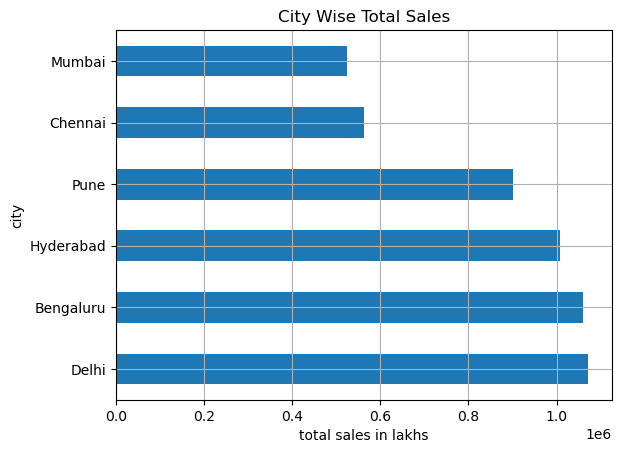

In [108]:
city_wise_perfomance.plot(kind="barh")
plt.xlabel("total sales in lakhs")
plt.ylabel("city")
plt.grid()
plt.title("City Wise Total Sales")
plt.show()

# Delhi is the best perfoming city
# Mumbai is the least perfoming city

In [47]:
#Analyzing monthly sales

monthly_perfomance=dff.groupby("Month")["Sales_Amount"].sum().sort_values(ascending=False)
monthly_perfomance

Month
3     782812.225
1     767376.100
12    558851.100
11    521574.850
7     444821.550
8     441765.850
4     398096.000
5     397329.600
9     338640.600
10    227918.525
6     162972.550
2      86612.500
Name: Sales_Amount, dtype: float64

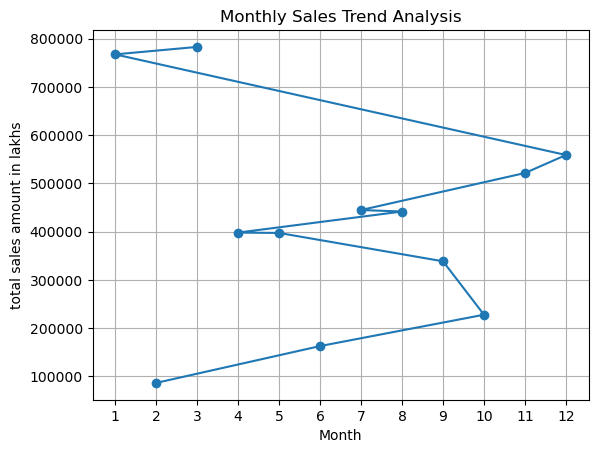

In [49]:
monthly_perfomance.plot(kind="line",marker="o")
plt.xticks(range(1,13))
plt.ylabel("total sales amount in lakhs")
plt.title("Monthly Sales Trend Analysis")
plt.grid()
plt.show()


# December got highest sales revenue in a year

In [62]:
total_sales=dff.groupby("Payment_Method")["Sales_Amount"].sum()
total_amount

Payment_Method
Card            935505.900
Cash            902350.925
Net Banking    1580642.750
Upi            1710271.875
Name: Sales_Amount, dtype: float64

In [63]:
no_of_orders=dff.groupby("Payment_Method")["Sales_Amount"].count()
no_of_orders

Payment_Method
Card           25
Cash           30
Net Banking    31
Upi            31
Name: Sales_Amount, dtype: int64

In [66]:
payment_analysis=pd.DataFrame({"Total_Sales":total_sales,
              "No_Of_Orders":no_of_orders}
            )
payment_analysis

,Total_Sales,No_Of_Orders
Payment_Method,,
Card,935505.900,25
Cash,902350.925,30
Net Banking,1580642.750,31
Upi,1710271.875,31


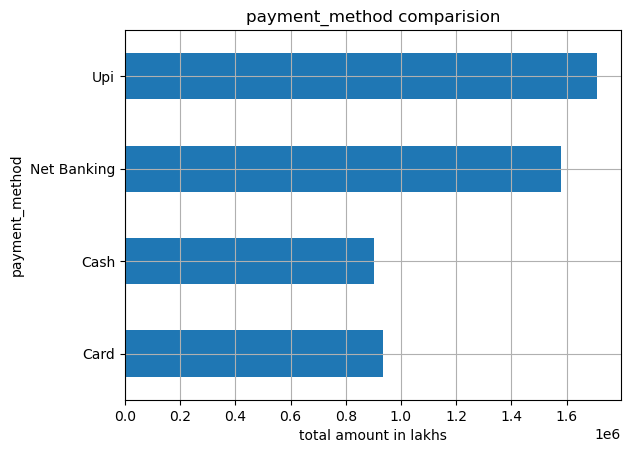

In [70]:
payment_analysis["Total_Sales"].plot(kind="barh")
plt.ylabel("payment_method")
plt.xlabel("total amount in lakhs")
plt.title("payment_method comparision")
plt.grid()
plt.show()

# Upi is the most used payment_method 

In [77]:
#category wise perfomance

dff["Category"].value_counts()

Category
Electronics    64
Accessories    53
Name: count, dtype: int64

In [80]:
category_sales=dff.groupby("Category")["Sales_Amount"].sum()
category_sales

Category
Accessories     393766.50
Electronics    4735004.95
Name: Sales_Amount, dtype: float64

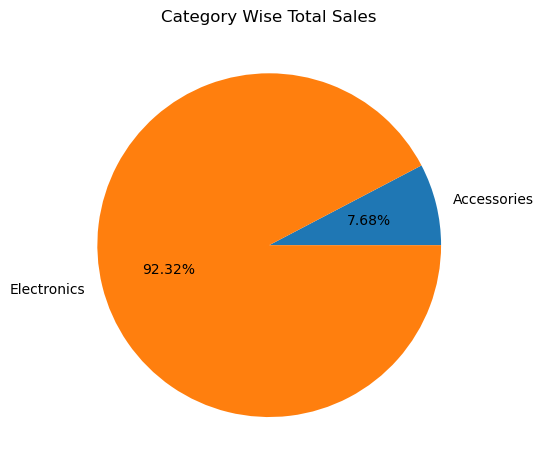

In [92]:
category_sales.plot(kind="pie",autopct="%1.2f%%",labels=category_sales.index)
plt.title("Category Wise Total Sales")
plt.ylabel("")
plt.tight_layout()
plt.show()


# Elecronics contributes more in total sales

In [98]:
# identify frequently purchased product

most_purchased_product=dff.groupby("Product")["Quantity"].sum().sort_values(ascending=False)
most_purchased_product

Product
Keyboard      78.000000
Monitor       58.000000
Tablet        52.000000
Headphones    43.889831
Mouse         38.000000
Laptop        37.000000
Phone         34.889831
Name: Quantity, dtype: float64

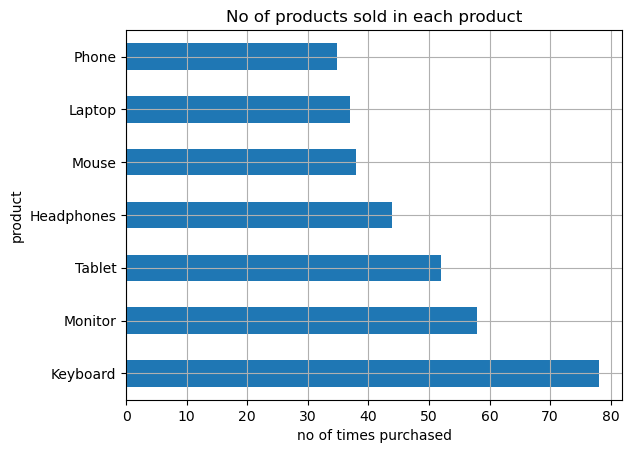

In [109]:
most_purchased_product.plot(kind="barh")
plt.ylabel("product")
plt.xlabel("no of times purchased")
plt.grid()
plt.title("No of products sold in each product")
plt.show()

# Keyboard is most frequently purchased item

In [103]:
#numeric columns comparision

numeric_cols = [
    "Quantity",
    "Unit_Price",
    "Discount_Pct",
    "Sales_Amount"
]
comparision= df[numeric_cols].corr()
comparision

,Quantity,Unit_Price,Discount_Pct,Sales_Amount
Quantity,1.000000,-0.022884,0.102769,0.305216
Unit_Price,-0.022884,1.000000,0.119391,0.810817
Discount_Pct,0.102769,0.119391,1.000000,0.237643
Sales_Amount,0.305216,0.810817,0.237643,1.000000


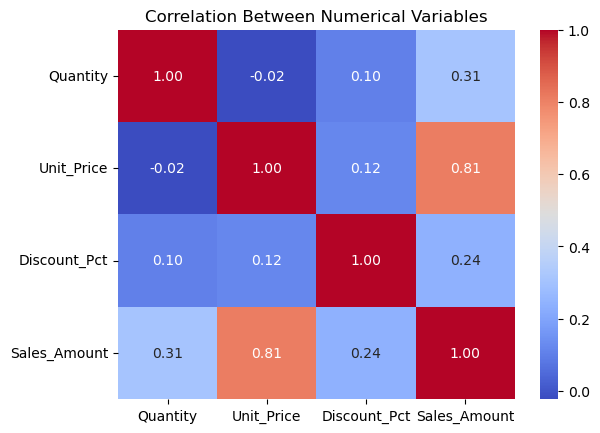

In [106]:
sns.heatmap(
    comparision,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Between Numerical Variables")
plt.show()

# Unit_Price and Sales_Amount has +ve Correlation